In [2]:
!wget -q "https://www.kaggle.com/api/v1/datasets/download/mohammadtalib786/retail-sales-dataset?datasetVersionNumber=1" -O retail.zip
!unzip -o retail.zip

Archive:  retail.zip
  inflating: retail_sales_dataset.csv  


In [3]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())


Shape: (1000, 9)

Columns:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [5]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [6]:
df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


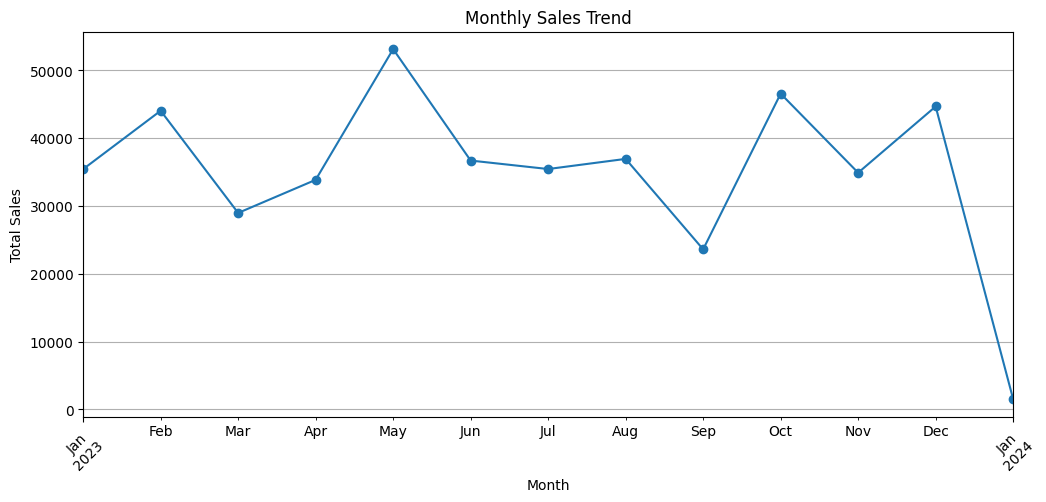

In [7]:
import matplotlib.pyplot as plt

monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum()

plt.figure(figsize=(12,5))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

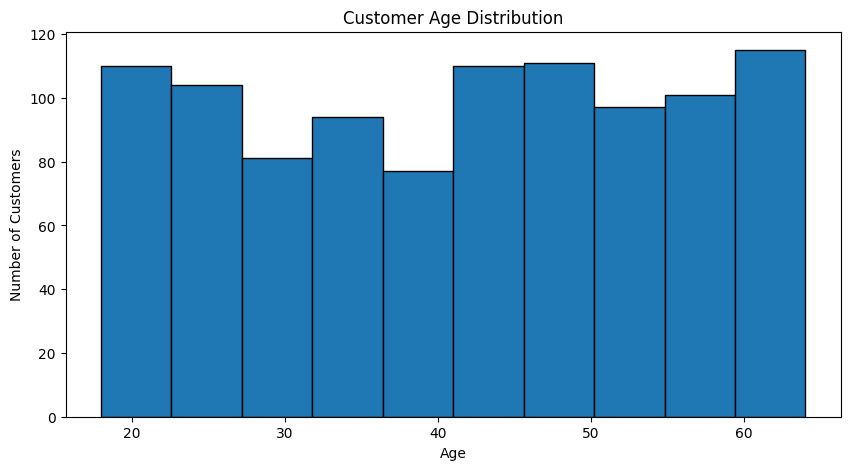

In [8]:
plt.figure(figsize=(10,5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

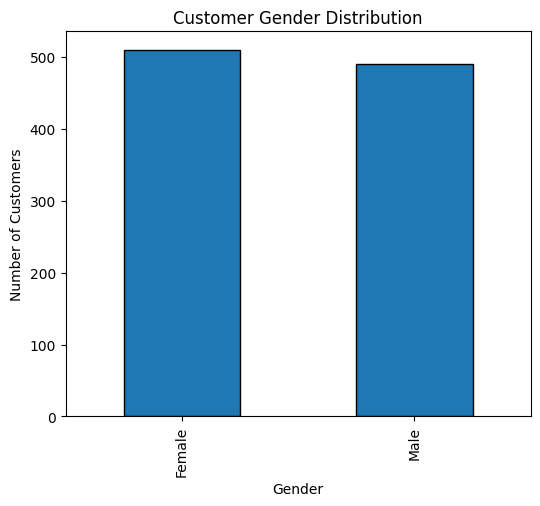

In [9]:
gender_count = df['Gender'].value_counts()

plt.figure(figsize=(6,5))
gender_count.plot(kind='bar', edgecolor='black')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

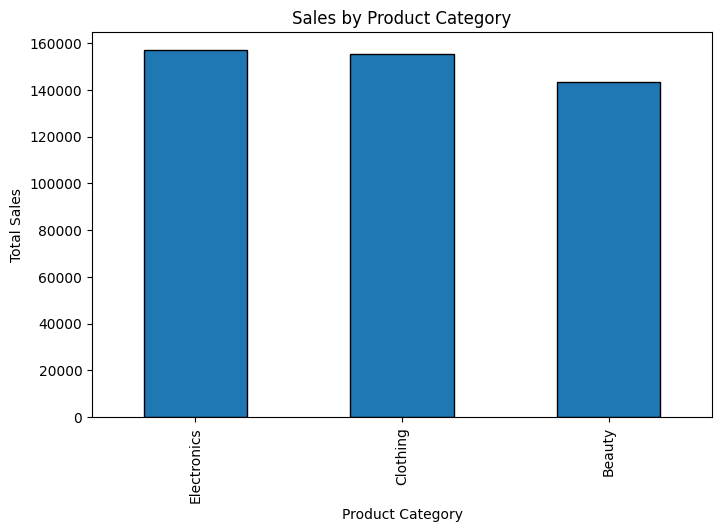

In [10]:
category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
category_sales.plot(kind='bar', edgecolor='black')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')

plt.show()

In [11]:
top_10_sales = df.nlargest(10, 'Total Amount')

top_10_sales[['Transaction ID', 'Customer ID',
              'Product Category', 'Quantity',
              'Price per Unit', 'Total Amount']]

,Transaction ID,Customer ID,Product Category,Quantity,Price per Unit,Total Amount
14,15,CUST015,Electronics,4,500,2000
64,65,CUST065,Electronics,4,500,2000
71,72,CUST072,Electronics,4,500,2000
73,74,CUST074,Beauty,4,500,2000
88,89,CUST089,Electronics,4,500,2000
92,93,CUST093,Beauty,4,500,2000
108,109,CUST109,Electronics,4,500,2000
117,118,CUST118,Electronics,4,500,2000
123,124,CUST124,Clothing,4,500,2000
138,139,CUST139,Beauty,4,500,2000


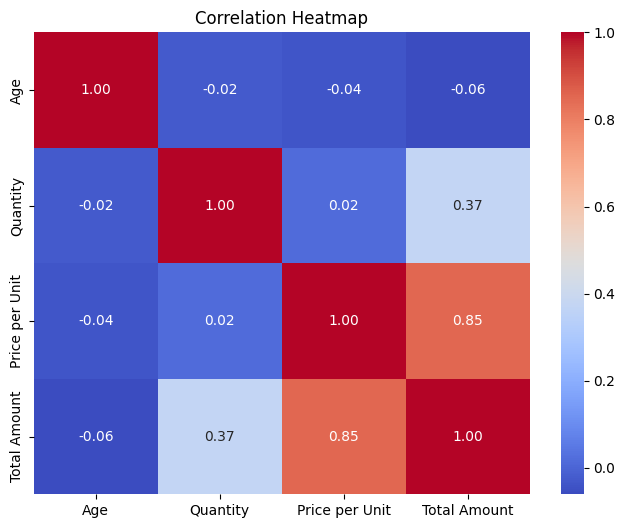

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

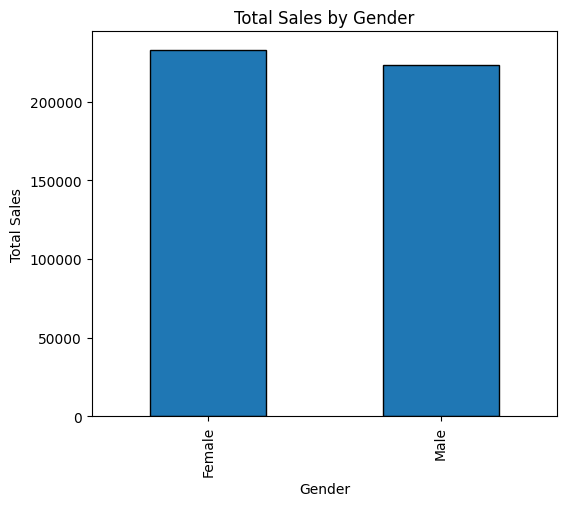

In [13]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

plt.figure(figsize=(6,5))
gender_sales.plot(kind='bar', edgecolor='black')

plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.show()

### Key Observations

- Monthly sales show variation across different months, indicating changes in sales performance over time.
- Customers belong to different age groups, showing a diverse customer base.
- The gender distribution shows the number of customers across different genders.
- Sales contribution varies across product categories, with some categories generating higher revenue than others.
- The correlation heatmap shows the relationships between numerical variables such as Age, Quantity, Price per Unit, and Total Amount.
- Sales also vary between genders, helping identify differences in customer spending patterns.

## Conclusion

The EDA of the retail sales dataset helped identify important patterns in customer demographics, sales trends, product categories, and purchasing behaviour. The visualizations and correlation analysis provide useful insights that can support business decision-making.

### Business Recommendations

1. Focus marketing efforts on the product categories that generate higher sales.
2. Use customer age and gender patterns to create more targeted marketing campaigns.
3. Monitor monthly sales trends and plan promotions during periods with lower sales.